# Practice Session 03: Find near-duplicates using shingling

Author: <font color="#2680EB">Bo-Yu Chen</font>

E-mail: <font color="#2680EB">8011chen@gmail.com</font>

AI used: <font color="#2680EB">chatGPT, I am using the free version and I cannot find the model name</font>

Date: <font color="#2680EB">08/10/2026</font>

In [1]:
# LEAVE AS-IS

# Required libraries
import gzip
import csv
import re
import random
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Romanization library
from transliterate import translit
from transliterate.exceptions import LanguageDetectionError

# Timing
from timeit import default_timer as timer


In [ ]:
# LEAVE AS-IS

# Input file
INPUT_FILENAME = "questions.csv.gz"

# Minimum number of words needed to read the questions
MIN_WORDS = 20

# IMPORTANT:
# 1. Set this to 2000 during development
# 2. Set this to 10000 once you have completed the development
MAX_QUESTIONS = 2000

# Array for storing questions
questions = []

with gzip.open(INPUT_FILENAME, "rt", encoding="utf-8") as input_file:
    
    questions_read = 0
    reader = csv.DictReader(input_file)
    headers = reader.fieldnames
    
    for line in reader:
            
        # Read line
        q1 = line["question1"]
        q2 = line["question2"]
        
        if min(len(q1.split()), len(q2.split())) >= MIN_WORDS:
            questions.append(q1)
            questions.append(q2)
            
            questions_read += 2
        
            if (MAX_QUESTIONS != -1) and (questions_read >= MAX_QUESTIONS):
                break

print(f"Read {len(questions)} questions")

Read 10000 questions


In [3]:
# LEAVE AS-IS

SAMPLE_SIZE = 3

for question in random.sample(questions, SAMPLE_SIZE):
    print(question)
    print()

What are good gifts for a foreign visitor to bring when they're invited to someone's home in Republic of Macedonia for the first time?

At 20°C, the solubility of LiF in water is 0.27 g per 100 mL, whereas that of LiBr is 167 g per 100 mL. Can you explain the relative solubility of the two salts?

What is likely theological significance of Muhammad saying “In heaven, Miriam, the mother of Jesus, will be one of my wives.” Hadith al-Siyuti 6/395?



# 1. Auxiliary functions <font color="#2680EB">[5%]</font>

<font size="+1" color="#2680EB">**Indicate how would you handle the case in which both lists are empty.** Include a justification, ideally a reference, justifying your choice.</font>

**Answer.** If both lists are empty:

* If both lists are both empty, they are the same. And we would like to measure the similarity between two lists, so if both lists are empty, assign 1 as their similarity would be logical.


<font size="+1" color="#2680EB">**Implement Jaccard similarity of lists.** Be consistent with your choice of handling of empty lists.</font>

In [4]:
def jaccard_similarity(list1, list2):
    
    # YOUR CODE HERE
    
    # if both are empty
    if not list1 and not list2:
        return 1.0
    
    set1 = set(list1)
    set2 = set(list2)
    
    union_count = len(set1.union(set2))
    intersection_count = len(set1.intersection(set2))
    sim = intersection_count / union_count
    
    return sim

<font size="+1" color="#2680EB">**Test your Jaccard similarity function,** with at least the test cases described above.</font>

In [5]:
# YOUR CODE HERE

def test_empty():
    set1 = []
    set2 = []
    print("testing Handling of empty lists")
    print(jaccard_similarity(set1, set2))
    assert(jaccard_similarity(set1, set2)==1)
    
def test_same():
    set1 = [2, 3, 7]
    set2 = [3, 2, 7]
    print("testing Two lists for which the jaccard similarity is 1.0")
    print(jaccard_similarity(set1, set2))
    assert(jaccard_similarity(set1, set2)==1)

def test_similar():
    set1 = [6, 2, 0, 11, 87, 81, 3, 20]
    set2 = [9, 1, 3, 65, 6, 4]
    print("testing Two lists for which the jaccard similarity is 1/6 (+- 0.001)")
    print(jaccard_similarity(set1, set2))
    print(abs(jaccard_similarity(set1, set2)-1/6))
    assert(abs(jaccard_similarity(set1, set2)-1/6)<0.001)

In [6]:
test_empty()
test_same()
test_similar()

testing Handling of empty lists
1.0
testing Two lists for which the jaccard similarity is 1.0
1.0
testing Two lists for which the jaccard similarity is 1/6 (+- 0.001)
0.16666666666666666
0.0


<font size="+1" color="#2680EB">**Implement your text cleaning function**</font>

In [7]:
def clean(text):
    # lower
    text = text.lower()
    
    # romanizing
    # AI (edited)
    try:
        text = translit(text, 'l1', reversed=True)
    except LanguageDetectionError:
        pass
    
    # remove space
    text = text.strip()
    
    # remove not letter or digit
    # AI (edited)
    text = re.sub(r'[^a-z0-9\s]', '', text)
    
    # change double space
    # AI (edited)
    text = re.sub(r'\s+', ' ', text).strip()

    return text

<font size="+1" color="#2680EB">**Test your text cleaning function.** Use [assert](https://realpython.com/python-assert-statement/), and cover all cases of the specification. Make sure your test cases are similar to questions in the dataset.</font>

In [8]:
# YOUR CODE HERE
# AI

def test_clean_function():
    # Test 1: Lowercase, Digit Retention, Punctuation Removal
    # Input matching dataset: Academic/Exam question
    q1_input = "My maths have become extremely weak and I am in class 12th. How to clear JEE exams?"
    q1_expected = "my maths have become extremely weak and i am in class 12th how to clear jee exams"
    assert clean(q1_input) == q1_expected, f"\nExpected: '{q1_expected}'\nGot:      '{clean(q1_input)}'"

    # Test 2: Romanization & Accent Handling (Ñ -> n, ó -> o)
    # Input matching dataset: Spanish/Multilingual phrasing
    q2_input = "¿Cómo can I improve my maths, Señor Ñoño?"
    q2_expected = "como can i improve my maths senor nono"
    assert clean(q2_input) == q2_expected, f"\nExpected: '{q2_expected}'\nGot:      '{clean(q2_input)}'"

    # Test 3: Leading, Trailing, and Internal Multi-Spaces
    # Input matching dataset: Legal hypothetical question with parentheses
    q3_input = "   If someone hits or stabs me (they act first)   and I kill them... what are the legal repercussions?   "
    q3_expected = "if someone hits or stabs me they act first and i kill them what are the legal repercussions"
    assert clean(q3_input) == q3_expected, f"\nExpected: '{q3_expected}'\nGot:      '{clean(q3_input)}'"

    # Test 4: Removal of URLs and Special Symbols
    # Input matching dataset: Question containing web references
    q4_input = "What are the legal repercussions under Section 302? See https://law.example.com/q?id=100_v1!"
    q4_expected = "what are the legal repercussions under section 302 see httpslawexamplecomqid100v1"
    assert clean(q4_input) == q4_expected, f"\nExpected: '{q4_expected}'\nGot:      '{clean(q4_input)}'"

    # Test 5: Comprehensive Edge Case (All 5 Rules Combined)
    # Input matching dataset: Complex question with heavy formatting
    q5_input = "  ¿¿¿Why did God make MEN so ugly (e.g.  trés  moche) & women show skin???  "
    q5_expected = "why did god make men so ugly eg tres moche women show skin"
    assert clean(q5_input) == q5_expected, f"\nExpected: '{q5_expected}'\nGot:      '{clean(q5_input)}'"

    print("All 5 tests passed successfully!")

# Run tests
test_clean_function()

All 5 tests passed successfully!


# 2. Implement an n-gram extractor <font color="#2680EB">[5%]</font>

<font size="+1" color="#2680EB">**Implement the ngram extractor.**</font>

In [9]:
MIN_TOKEN_LENGTH = 4

def ngrams(text, size):
    
    text = clean(text)
    
    # YOUR CODE HERE
    words = [word for word in text.split() if len(word)>=MIN_TOKEN_LENGTH]

    result = []
    start_idx = 0
    while start_idx + size <= len(words):
        result.append(" ".join(words[start_idx:start_idx+size]))
        start_idx += 1
    
    return(result)

<font size="+1" color="#2680EB">**Test your function 'ngrams'**. Consider ngrams of size 3, select three questions from the dataset, and check their ngrams using assert.</font>

In [10]:
# YOUR CODE HERE
# AI

# Select 3 sample questions
dataset_questions = [
    "What are the best programming languages for data science?",
    "How can I quickly improve my natural language processing skills?",
    "Why is text preprocessing important before training machine learning models?"
]

def expected_ngrams(text, size=3, min_len=MIN_TOKEN_LENGTH):
    text = clean(text)
    words = [word for word in text.split() if len(word) >= min_len]

    return [
        " ".join(words[i:i + size])
        for i in range(len(words) - size + 1)
    ]

# Test ngrams(text, 3) across the three questions
for i, question in enumerate(dataset_questions, start=1):
    result = ngrams(question, 3)
    expected = expected_ngrams(question, 3, MIN_TOKEN_LENGTH)
    
    # Assert return type is a list
    assert isinstance(result, list), f"Question {i}: Output must be a list, but got {type(result)}."
    
    # Assert every item in the list is a string (not a list)
    assert all(isinstance(gram, str) for gram in result), f"Question {i}: All items in ngrams must be strings!"
    
    # Assert the ngrams content matches expectations
    assert result == expected, f"Question {i} mismatch!\nExpected: {expected}\nGot: {result}"
    
    print(f"✓ Question {i} passed ({len(result)} n-grams generated):")
    print(f"  {result}\n")

print("All 3 assertions passed successfully!")

✓ Question 1 passed (4 n-grams generated):
  ['what best programming', 'best programming languages', 'programming languages data', 'languages data science']

✓ Question 2 passed (4 n-grams generated):
  ['quickly improve natural', 'improve natural language', 'natural language processing', 'language processing skills']

✓ Question 3 passed (6 n-grams generated):
  ['text preprocessing important', 'preprocessing important before', 'important before training', 'before training machine', 'training machine learning', 'machine learning models']

All 3 assertions passed successfully!


# 3. Estimation of brute force all-pairs method  <font color="#2680EB">[10%]</font>

In [11]:
# LEAVE AS-IS

def time_brute_force_similarities(texts, limit, ngram_size):
    if limit > len(texts):
        raise ValueError("Limit should be less than or equal than the number of texts")
        
    # Start a timer
    start = timer()

    # Iterate through document identifiers
    for docid1 in range(np.min([len(texts), limit])):

        # Extract ngrams from doc1
        doc1 = texts[docid1]
        ngrams1 = ngrams(doc1, ngram_size)

        # Iterate through document identifiers larger than doc2
        for docid2 in range(docid1+1, np.min([len(questions), limit])):
                         
            # Extract ngrams from doc2
            doc2 = texts[docid2]
            ngrams2 = ngrams(doc2, ngram_size)

            # Compute similarity
            similarity = jaccard_similarity(ngrams1, ngrams2)

    end = timer()
    return(end - start)

<font size="+1" color="#2680EB">**Generate the data for the requested plots**.</font>

In [34]:
num_texts = []
time_required = []

# YOUR CODE HERE  
# AI
for limit in range(1, 1002, 200):
    num_texts.append(limit)
    time_required.append(
        time_brute_force_similarities(questions, limit, 3)
    )


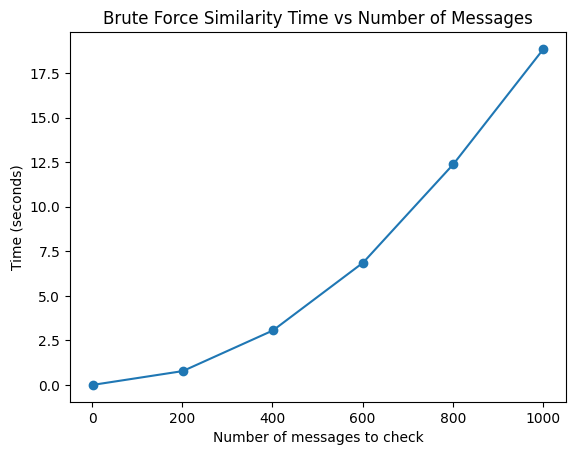

In [35]:
# Now plot this data; remember to add a title and label for the x and y axis.

# YOUR CODE HERE
plt.plot(num_texts, time_required, marker='o')

plt.title("Brute Force Similarity Time vs Number of Messages")
plt.xlabel("Number of messages to check")
plt.ylabel("Time (seconds)")

plt.show()

<font size="+1" color="#2680EB">**Find a quadratic approximation of the required time for bruteforce**. Use two significant digits for the coefficient. The code will plot your estimation and the experimental value.</font>

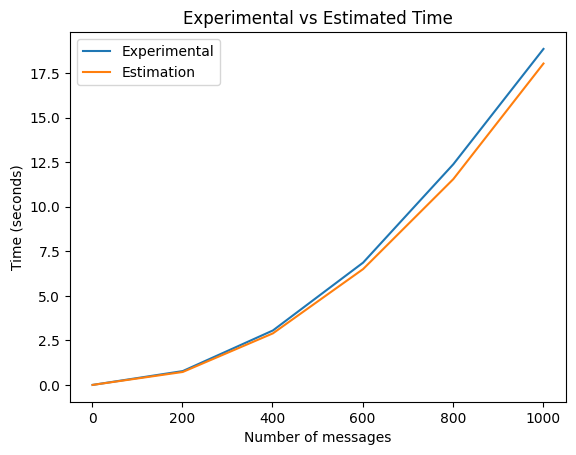

In [36]:
# YOUR CODE HERE

time_estimated = [(0.000018 * (n ** 2)) for n in num_texts]

plt.plot(num_texts, time_required, label="Experimental")
plt.plot(num_texts, time_estimated, label="Estimation")

plt.xlabel('Number of messages')
plt.ylabel('Time (seconds)')
plt.title('Experimental vs Estimated Time')

plt.legend()
plt.show()

<font size="+1" color="#2680EB">**Estimate how long the brute-force approach would take for the entire dataset**. It contains 25K questions. Express your estimation first in seconds, and then in human terms (e.g., hours, or days) using [timedelta](https://docs.python.org/3/library/datetime.html#timedelta-objects) and [humanize](https://pypi.org/project/humanize/).</font>

In [15]:
from datetime import timedelta
import humanize

# AI edited

n = 25000

estimated_seconds = 0.000018 * (n ** 2)

print(f"Estimated time in seconds: {estimated_seconds:.2f}")

estimated_time = timedelta(seconds=estimated_seconds)

print(f"Estimated time: {humanize.naturaldelta(estimated_time)}")


Estimated time in seconds: 11250.00
Estimated time: 3 hours


# 4. Computing the doc-ngram matrix <font color="#2680EB">[20%]</font>

## 4.1 Create list of all ngrams

<font size="+1" color="#2680EB">**Create an ngram_to_index dictionary**.</font>

In [38]:
NGRAM_SIZE = 3

ngram_to_index = {}
index_to_ngram = {}
next_index = 0

for question in questions:
    all_ngrams = ngrams(question, NGRAM_SIZE)
    
    # YOUR CODE HERE
    for ngram in all_ngrams:
        if ngram in ngram_to_index:
            continue
        ngram_to_index[ngram] = next_index
        index_to_ngram[next_index] = ngram
        next_index += 1
            
num_distinct_ngrams = next_index

print(f"There are {num_distinct_ngrams} distinct ngrams in the {len(questions)} questions")

There are 91442 distinct ngrams in the 10000 questions


<font size="+1" color="#2680EB">**Write test_ngram_index_consistency**.</font>

In [39]:
# AI

def test_ngram_index_consistency(ngram_to_index, index_to_ngram, text):
    for ngram in ngrams(text, NGRAM_SIZE):
        index = ngram_to_index[ngram]
        assert index_to_ngram[index] == ngram, \
            f"Mismatch: index {index} maps to '{index_to_ngram[index]}', expected '{ngram}'"

    print(f"Test passed for: '{text}'")


test_ngram_index_consistency(ngram_to_index, index_to_ngram, "pending many days")
test_ngram_index_consistency(ngram_to_index, index_to_ngram, "answer this question")

Test passed for: 'pending many days'
Test passed for: 'answer this question'


## 2.2 Create table ngrams x documents

In [40]:
# LEAVE AS-IS

# Create dense matrix in which every cell contains the value "False"
M_ngram_doc = np.full((num_distinct_ngrams, len(questions)), False)

# Print the number of rows and columns of this matrix
# numpy.matrix.shape is a tuple (0=rows, 1=columns)
print(f"Matrix has {M_ngram_doc.shape[0]} rows (distinct shingles)")
print(f"Matrix has {M_ngram_doc.shape[1]} columns (distinct documents)")

Matrix has 91442 rows (distinct shingles)
Matrix has 10000 columns (distinct documents)


<font size="+1" color="#2680EB">**Fill-in the M_ngram_doc matrix**. Use the template below.</font>

In [41]:
for docid in range(len(questions)):
    question = questions[docid]
    all_ngrams = ngrams(question, NGRAM_SIZE)
    for ngram_str in all_ngrams:
        # YOUR CODE HERE
        ngram_idx = ngram_to_index[ngram_str]
        M_ngram_doc[ngram_idx, docid] = True

<font size="+1" color="#2680EB">**Print the density of the matrix**. This is the fraction of cells that are non-zero. Print this as a percentage, using 3 decimals.</font>

In [42]:
# YOUR CODE HERE
density = np.count_nonzero(M_ngram_doc) / M_ngram_doc.size
print(f"Density of the matrix: {density * 100:.3f}%")

Density of the matrix: 0.013%


In [43]:
# LEAVE AS-IS

test_docid=391
print(f"Positions of non-zeros in column of docid {test_docid} of M_ngram_doc")
print()

print(f"Clean text:\n {clean(questions[test_docid])}")
ngrams_doc_tested = [("%d (%s)" % (i, index_to_ngram[i])) for i in range(num_distinct_ngrams) if M_ngram_doc[i, test_docid] == True]

print()
print(f"Non-zeros in corresponding row:\n {ngrams_doc_tested}")


Positions of non-zeros in column of docid 391 of M_ngram_doc

Clean text:
 what would have happened if the japanese had not attacked pearl harbor would the us have still gotten into the war with germany

Non-zeros in corresponding row:
 ['4215 (what would have)', '4216 (would have happened)', '4217 (have happened japanese)', '4218 (happened japanese attacked)', '4219 (japanese attacked pearl)', '4220 (attacked pearl harbor)', '4221 (pearl harbor would)', '4222 (harbor would have)', '4223 (would have still)', '4224 (have still gotten)', '4225 (still gotten into)', '4226 (gotten into with)', '4227 (into with germany)']


# 3. Implement a permutation generator <font color="#2680EB">[10%]</font>

<font size="+1" color="#2680EB">**Implement the function "random_permutation"**. Follow the specification above.</font>

In [44]:
def random_permutation(k):
    # YOUR CODE HERE
    l = list(range(k))
    random.shuffle(l)
    return l

In [45]:
# LEAVE AS-IS

# Permute a list according to a permutation
def permuter(original_list, permutation):
    permuted_list = []
    for index in permutation:
        permuted_list.append(original_list[index])
    return permuted_list

# Code for testing permutations

# Original lists
original_list_1 = ["1 (test1)", "2 (test2)", "3 (test3)", "4 (test4)", "5 (test5)"]
original_list_2 = ["1 (alpha)", "2 (gamma)", "3 (beta)", "4 (delta)", "5 (epsilon)"]
assert len(original_list_1) == len(original_list_2)
lists_len = len(original_list_1)

print("Original:")
print(original_list_1)
print(original_list_2)
print()

# Two permutation tests
print("Permuted (first test):")
permutation_1 = random_permutation(lists_len)
print(permuter(original_list_1, permutation_1))
print(permuter(original_list_2, permutation_1))
print()

print("Permuted (second test)")
permutation_2 = random_permutation(lists_len)
print(permuter(original_list_1, permutation_2))
print(permuter(original_list_2, permutation_2))

Original:
['1 (test1)', '2 (test2)', '3 (test3)', '4 (test4)', '5 (test5)']
['1 (alpha)', '2 (gamma)', '3 (beta)', '4 (delta)', '5 (epsilon)']

Permuted (first test):
['5 (test5)', '1 (test1)', '4 (test4)', '3 (test3)', '2 (test2)']
['5 (epsilon)', '1 (alpha)', '4 (delta)', '3 (beta)', '2 (gamma)']

Permuted (second test)
['3 (test3)', '5 (test5)', '2 (test2)', '1 (test1)', '4 (test4)']
['3 (beta)', '5 (epsilon)', '2 (gamma)', '1 (alpha)', '4 (delta)']


# 4. Compute the signature of each document <font color="#2680EB">[20%]</font>

In [46]:
# LEAVE AS-IS

NUM_PERMUTATIONS = 5

permutations = []

# Create the permutations
for i in range(NUM_PERMUTATIONS):
    permutation = random_permutation(num_distinct_ngrams)
    permutations.append(random_permutation(num_distinct_ngrams))
    
# Visualize the permutations by printing their first 4 elements
for i in range(len(permutations)):
    permutation = permutations[i]
    print("Permutation %d: %d, %d, %d, %d, ..." % (i,
                permutation[0], permutation[1], permutation[2], permutation[3] ))

Permutation 0: 49067, 74360, 51032, 14127, ...
Permutation 1: 14029, 70248, 42293, 90546, ...
Permutation 2: 77727, 32030, 59402, 25209, ...
Permutation 3: 5877, 9241, 55163, 37900, ...
Permutation 4: 39198, 17536, 60159, 12913, ...


In [47]:
# LEAVE AS-IS

# Find the first ngram in a document, according to a permutation
def find_first_one(docid, permutation):

    # The instructor used AI to optimize this function (Gemini 3.6 Flash)
    
    # Extract the column docid in the order of the permutation
    matches = M_ngram_doc[permutation, docid]
    
    # Check if there are any "True" in the column
    if not matches.any():
        return -1
        
    # Function argmax returns the index of the first True value
    return permutation[np.argmax(matches)]

<font size="+1" color="#2680EB">**Implement code to create M_signature_doc**.</font>

In [48]:
# Create empty matrix
M_signature_doc = np.full((NUM_PERMUTATIONS, len(questions)), np.nan)

for permutation_num in range(NUM_PERMUTATIONS):
    print(f"Creating signatures for permutation {permutation_num+1} of {NUM_PERMUTATIONS}")
    permutation = permutations[permutation_num]
    
    start = timer()
    print(f"- There are {len(questions)} documents")
    # YOUR CODE HERE
    for question_num in range(len(questions)):
        M_signature_doc[permutation_num, question_num] = find_first_one(question_num, permutation)
    end = timer()
    print(f"- took {end-start} secs")

# The code above should take less than 5 minutes for 10K documents

Creating signatures for permutation 1 of 5
- There are 10000 documents
- took 46.220733799999834 secs
Creating signatures for permutation 2 of 5
- There are 10000 documents
- took 44.633981400000266 secs
Creating signatures for permutation 3 of 5
- There are 10000 documents
- took 44.02569330000006 secs
Creating signatures for permutation 4 of 5
- There are 10000 documents
- took 45.24728620000042 secs
Creating signatures for permutation 5 of 5
- There are 10000 documents
- took 44.7835184000005 secs


In [49]:
# LEAVE AS-IS

def extract_ngrams(docid):
    return [x for x in range(num_distinct_ngrams) if M_ngram_doc[x, docid] == True]

def extract_signature(docid):
    return [M_signature_doc[x, docid] for x in range(NUM_PERMUTATIONS)]


In [50]:
# Pick two documents that are similar

TEST_DOCID_1 = 158
TEST_DOCID_2 = 159

# LEAVE AS-IS

def print_sig(texts, M_ngram_doc, M_signature_doc, i):
    print(f"Document #{i}")
    print(f"Text      : {texts[i]}")
    print(f"Clean     : {clean(texts[i])}")
    
    ngrams = extract_ngrams(i)
    signature = extract_signature(i)
    
    print(f"Ngrams    : {ngrams}")
    print(f"Signature : {signature}")
    
    return (ngrams, signature)

# Print two messages and their signatures

(ng1,sig1) = print_sig(questions, M_ngram_doc, M_signature_doc, TEST_DOCID_1 )
print()
(ng2,sig2) = print_sig(questions, M_ngram_doc, M_signature_doc, TEST_DOCID_2 )
print()

print(f"Ngrams similarity     : {jaccard_similarity(ng1,ng2)}")
print(f"Signatures similarity : {jaccard_similarity(sig1,sig2)}")

Document #158
Text      : I want a real and effective way to make $ 500 per month with the knowledge that I have no money to invest?
Clean     : i want a real and effective way to make 500 per month with the knowledge that i have no money to invest
Ngrams    : [1694, 1695, 1696, 1697, 1698, 1699, 1700, 1701, 1702]
Signature : [np.float64(1700.0), np.float64(1702.0), np.float64(1702.0), np.float64(1695.0), np.float64(1701.0)]

Document #159
Text      : The real effective way to make $ 500 per month with the knowledge that I have no money to invest?
Clean     : the real effective way to make 500 per month with the knowledge that i have no money to invest
Ngrams    : [1695, 1696, 1697, 1698, 1699, 1700, 1701, 1702]
Signature : [np.float64(1700.0), np.float64(1702.0), np.float64(1702.0), np.float64(1695.0), np.float64(1701.0)]

Ngrams similarity     : 0.8888888888888888
Signatures similarity : 1.0


# 5. Compare all pairs of signatures <font color="#2680EB">[10%]</font>

<font size="+1" color="#2680EB">**Implement all-pairs comparison of signatures**. Keep pairs in which there is a partial or full signature match.</font>

In [51]:
# List of possible duplicates
# Keys should be tuples (docid1, docid2)
# Values should be the similarity between the signatures of those docs.
# Only store if they are partial or full matches
is_possible_duplicate = {}
count_near_duplicates = {}

# Iterate through all documents
start = timer()
print(f"There are {len(questions)} documents")

for docid1 in range(len(questions)):
    if docid1 % 500 == 0:
        print(f"{docid1} scanned ({int(timer()-start)}s)")

    # Extract the signature of the doc1
    signature1 = extract_signature(docid1)

    # Iterate through documents with docid larger than doc1
    for docid2 in range(docid1+1, len(questions)):

        # Extract signature of doc2
        signature2 = extract_signature(docid2)

        # Compute similarity and keep in case of partial or full match
        # In that case, increase the counting of near duplicates of doc1
        # YOUR CODE HERE
        estimated_similarity = jaccard_similarity(signature1, signature2)
        if estimated_similarity>=0.2:
            is_possible_duplicate[(docid1, docid2)] = estimated_similarity
            
            if docid1 not in count_near_duplicates:
                count_near_duplicates[docid1] = 0
            if docid2 not in count_near_duplicates:
                count_near_duplicates[docid2] = 0
            
            count_near_duplicates[docid1] += 1
            count_near_duplicates[docid2] += 1
        
print("Done")


There are 10000 documents
0 scanned (0s)
500 scanned (8s)
1000 scanned (17s)
1500 scanned (25s)
2000 scanned (32s)
2500 scanned (39s)
3000 scanned (46s)
3500 scanned (52s)
4000 scanned (57s)
4500 scanned (62s)
5000 scanned (67s)
5500 scanned (71s)
6000 scanned (75s)
6500 scanned (78s)
7000 scanned (81s)
7500 scanned (83s)
8000 scanned (85s)
8500 scanned (87s)
9000 scanned (88s)
9500 scanned (89s)
Done


In [52]:
# LEAVE AS-IS

for sim in (0.2, 0.4, 0.6, 0.8, 1.0):
    print(f"Random pair with similarity {sim}")
    pairs = [pair for pair, similarity in is_possible_duplicate.items() if (abs(similarity  - sim) <= 1e-3)]
    (docid1, docid2) = random.choice(pairs)
    q1 = questions[docid1]
    q2 = questions[docid2]

    print(f"Question 1      : ({docid1}) {q1}")
    print(f"Question 2      : ({docid2}) {q2}")
    print(f"Signatures sim. : {is_possible_duplicate[(docid1,docid2)]}")    
    print(f"N-gram sim.     : {jaccard_similarity(ngrams(q1,3), ngrams(q2,3)):.2f}")
    
    print()


Random pair with similarity 0.2
Question 1      : (6915) How cold can the Gobi Desert get, and how do its average temperatures compare to the ones in other deserts?
Question 2      : (9282) How cold can the Gobi Desert get, and how do its average temperatures compare to the ones in the Dasht-e Margo?
Signatures sim. : 0.2
N-gram sim.     : 0.56

Random pair with similarity 0.4
Question 1      : (59) What hotel in Dehradun Hill-station would be safe for unmarried couples, without the harassment of police, hotel staff, and moral police?
Question 2      : (6702) What hotel in Kurseong Hill-station would be safe for unmarried couples, without the harassment of police, hotel staff, and moral police?
Signatures sim. : 0.4
N-gram sim.     : 0.62

Random pair with similarity 0.6
Question 1      : (5107) What was the significance of the battle of Somme, and how did this battle compare and contrast to the Battle of Dunkirk?
Question 2      : (9541) What was the significance of the battle of Somm

<font size="+1" color="#2680EB">**Answer the question below** regarding the differences you observe between signatures similarity and n-gram similarities.</font>

**Answer.** Why do the signature-based similarities and the n-grams similarities differ?

* Signature based similarities is only an esitimation of the n-grams similarities. Theoretically, signature-based similarities will get close to n-grams similarities as the permutation number increases. And currently, the permuation number is not large enough.


# 6. Describe near-duplicates <font color="#2680EB">[20%]</font>

<font size="+1" color="#2680EB">**Print questions having many near-duplicates**. For each of them, print up to 5 of its near-duplicate elements.</font>

In [53]:
# Keep track of which questions we have already printed
docids_in_output = {}

# Iterate through the questions with more duplicates
for top_q in sorted(count_near_duplicates, key=count_near_duplicates.get, reverse=True):

    # Skip questions that have already been printed
    # as near-duplicates of another question
    if top_q in docids_in_output:
        continue
    docids_in_output[top_q] = True
    
    # Skip questions that have less than 5 near-duplicates
    if count_near_duplicates[top_q] < 5:
        continue
    
    # Print the question
    print()
    print(f"Question {top_q} has many duplicates")
    print(f"Text: {questions[top_q]}")
    
    # Print up to 3 near-duplicates of that question
    # Keep track of how many you "printed" out of how many "existed"
    num_printed = 0
    num_existed = 0
    
    # YOUR CODE HERE
    for duplicate_pair in is_possible_duplicate.keys():
        if top_q in duplicate_pair:
            duplicate_pair_set = set(duplicate_pair)
            duplicate_pair_set.remove(top_q)
            duplicate = duplicate_pair_set.pop()
            if not duplicate in docids_in_output:
                docids_in_output[duplicate] = True
                print(questions[duplicate])
                num_printed += 1
                
        if num_printed>=3:
            break
    num_existed = count_near_duplicates[top_q]      
            
    
    print(f"Printed {num_printed}/{num_existed} near-duplicates")



Question 243 has many duplicates
Text: What hotel in Chandigarh would be safe for unmarried couples, without the harassment of police, hotel staff, and moral police?
What hotel in Shimla Hill-station would be safe for unmarried couples, without the harassment of police, hotel staff, and moral police?
What hotel in Dehradun Hill-station would be safe for unmarried couples, without the harassment of police, hotel staff, and moral police?
What hotel in Pelling Hill-station would be safe for unmarried couples, without the harassment of police, hotel staff, and moral police?
Printed 3/284 near-duplicates

Question 714 has many duplicates
Text: What hotel in Fatehpur would be safe for unmarried couples, without the harassment of police, hotel staff, and moral police?
What hotel in Lachung Hill-station would be safe for unmarried couples, without the harassment of police, hotel staff, and moral police?
What hotel in Saharanpur would be safe for unmarried couples, without the harassment of po

<font size="+1" color="#2680EB">**Answer the questions below** regarding the questions that have many near-duplicates.</font>

**Answer.** 

Provide two examples of questions having many near-duplicates that seem to be machine generated:

* Example 1:
What hotel in Bhopal would be safe for unmarried couples, without the harassment of police, hotel staff, and moral police?
What hotel in Shimla Hill-station would be safe for unmarried couples, without the harassment of police, hotel staff, and moral police?
What hotel in Dehradun Hill-station would be safe for unmarried couples, without the harassment of police, hotel staff, and moral police?
What hotel in Pelling Hill-station would be safe for unmarried couples, without the harassment of police, hotel staff, and moral police?

Example 2:
How can we get best Online Tutorials or educational videos or youtube videos or OpenCourseWare or mooc for preparation of SAT?
How can we get best Online Tutorials or educational videos or youtube videos or OpenCourseWare or mooc for preparation of GRE?
How can we get best Online Tutorials or educational videos or youtube videos or OpenCourseWare or mooc to learn MacBook repairing?
How can we get best Online Tutorials or educational videos or youtube videos or OpenCourseWare or mooc to learn Laptop repairing?

Why do you think someone would issue that many near-duplicate questions? Provide a plausible conjecture for one of them.

* A website or an app want to promote it self to the public or to the search engine, so they generated a lot of similar questions on the forum. For example, "How can we get best Online Tutorials or educational videos or youtube videos or OpenCourseWare or mooc for preparation of SAT?", this question might be generated by OpenCourseWare.

Write a question that seems to have been legitimately asked in two very similar ways in the platform. This question may not have many near-duplicates. Copy-paste two ways in which this question was written. Highlight in boldface the differences between the two formulations (perhaps a single word).

* Question 1678

If you could go back in time and change one **thing about** your life, what would it be and why?

If you could go back in time and change one **event in** your life, what would it be and why?



<font size="+2" color="#00A365">I hereby declare that I completed this practice myself, that I have not copied it from others, or from external sources without citing them, and that I have followed the generative AI instructions stated above.</font>